# Spoken Grammar Scoring Engine (v2)

**Goal:** predict a continuous MOS grammar score (0–5) for 45–60 s English speech clips.  
**Metrics:** RMSE and Pearson correlation (out-of-fold on train, plus in-sample training RMSE as required).

## Approach in one paragraph
Audio is decoded once in parallel on all CPU cores, which also yields acoustic/fluency features (speech ratio, pauses, loudness).
Whisper transcribes the clips on **all GPUs at once** (one model copy per GPU, chunk-batched).
The training labels contain a separate group of **0 scores (~5%)** that sits outside the 1–5 rubric, so the model has **two stages**:

1. **Unscorable detector:** a logistic regression on acoustic + transcript features gives `p0`, the probability that a clip is a 0.
2. **Grammar regressor:** DeBERTa-v3 fine-tuned on transcripts of clips scored 1–5 only, with 5-fold CV, **two folds training at once (one per GPU)** and mixed precision.

Final score = `(1 - p0) × regressor_score`, the expected value under both stages (the MSE-optimal combination), clipped to [0, 5].

**Kaggle settings:** GPU T4 x2, Internet ON.

## 1. Setup and configuration

In [1]:
import os, re, gc, glob, random, warnings, threading, queue
import numpy as np, pandas as pd, torch, librosa, soundfile as sf
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from concurrent.futures import ThreadPoolExecutor
from scipy.stats import pearsonr
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

CFG = dict(
    # --- ASR ---
    asr_model          = "openai/whisper-medium.en",
    asr_batch          = 24,     # 30 s chunks per forward pass, per GPU (lower to 16 on OOM)
    asr_clips_per_call = 96,     # clips handed to the pipeline per call (~3 chunks each)
    # --- text regressor ---
    text_model  = "microsoft/deberta-v3-base",
    n_folds     = 5,
    epochs      = 5,
    lr          = 2e-5,
    batch_size  = 8,
    eval_batch  = 64,
    max_len     = 256,
    warmup      = 0.1,
    amp         = True,          # fp16 autocast on fp32 weights (set False if you see NaN losses)
    # --- misc ---
    zero_cut    = 0.5,           # labels below this are treated as the 'unscorable' group
    sr          = 16000,
    seed        = 42,
    out_dir     = "/kaggle/working",
)
N_GPUS = torch.cuda.device_count()
DEVICES = [f"cuda:{i}" for i in range(N_GPUS)] or ["cpu"]

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["seed"])

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a, float) - np.asarray(b, float)) ** 2)))

print("Devices:", DEVICES, "| CPU cores:", os.cpu_count())

Devices: ['cuda:0', 'cuda:1'] | CPU cores: 4


## 2. Data discovery
Paths are found automatically under `/kaggle/input`. The sample submission is used only for its column names; the rows come from `test.csv` (one per test file).

In [2]:
INPUT = "/kaggle/input"
def find_one(pattern):
    hits = sorted(glob.glob(f"{INPUT}/**/{pattern}", recursive=True))
    assert hits, f"{pattern} not found under {INPUT}"
    return hits[0]

train_df = pd.read_csv(find_one("train.csv"))
test_df  = pd.read_csv(find_one("test.csv"))
sub_cols = pd.read_csv(find_one("*submission*.csv"), nrows=1).columns

def file_col(df):
    return next((c for c in df.columns if "file" in c.lower() or "name" in c.lower()), df.columns[0])
FNAME, TEST_FNAME = file_col(train_df), file_col(test_df)
LABEL = "label"
SUB_FNAME = next((c for c in sub_cols if "file" in c.lower() or "name" in c.lower()), sub_cols[0])
SUB_LABEL = "label" if "label" in sub_cols else [c for c in sub_cols if c != SUB_FNAME][0]

# index all audio once, then resolve CSV names (with or without extension)
AUDIO_EXT = (".wav", ".mp3", ".flac", ".ogg", ".m4a")
index = {}
for p in glob.glob(f"{INPUT}/**/*", recursive=True):
    if p.lower().endswith(AUDIO_EXT):
        b = os.path.basename(p)
        for k in (b, os.path.splitext(b)[0]):
            index.setdefault(k, []).append(p)

def resolve(name, split):
    b = os.path.basename(str(name).strip())
    cands = index.get(b) or index.get(os.path.splitext(b)[0]) or []
    pref = [c for c in cands if f"/{split}" in c.lower()]
    return (pref or cands or [None])[0]

train_df["path"] = [resolve(f, "train") for f in train_df[FNAME]]
test_df["path"]  = [resolve(f, "test")  for f in test_df[TEST_FNAME]]
print(f"train {train_df.shape}, test {test_df.shape}")
print("missing audio -> train:", train_df.path.isna().sum(), "test:", test_df.path.isna().sum())

train (769, 3), test (216, 3)
missing audio -> train: 0 test: 0


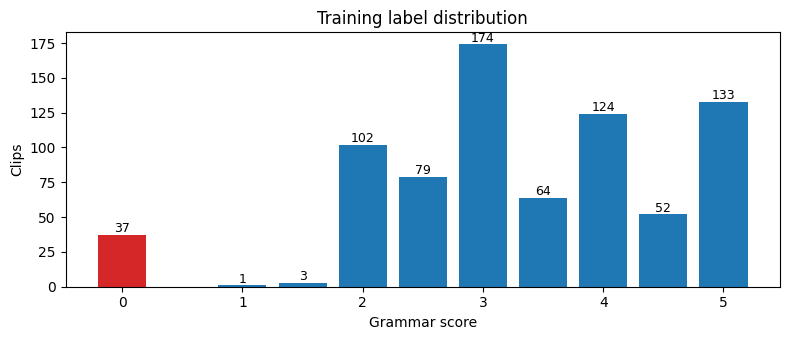

0-score clips: 37 / 769


In [3]:
# Label distribution: note the isolated group at 0, outside the 1-5 rubric
labels = train_df[LABEL].astype(float).values
fig, ax = plt.subplots(figsize=(8, 3.5))
vals, cnts = np.unique(labels, return_counts=True)
ax.bar(vals, cnts, width=0.4, color=["#d62728" if v < CFG["zero_cut"] else "#1f77b4" for v in vals])
for v, c in zip(vals, cnts):
    ax.text(v, c + 2, str(c), ha="center", fontsize=9)
ax.set(title="Training label distribution", xlabel="Grammar score", ylabel="Clips")
plt.tight_layout(); plt.show()
print(f"0-score clips: {(labels < CFG['zero_cut']).sum()} / {len(labels)}")

## 3. Audio loading and acoustic features (parallel, all CPU cores)
Each clip is decoded once at 16 kHz mono. In the same pass we compute fluency/quality features used by the unscorable detector:
duration, loudness (RMS), seconds of speech, speech ratio, number and total length of pauses longer than 0.5 s.

In [4]:
SR = CFG["sr"]

def load_with_feats(path):
    try:
        y, _ = librosa.load(path, sr=SR, mono=True)
        y = y.astype(np.float32)
    except Exception:
        y = np.zeros(SR, dtype=np.float32)
    dur = len(y) / SR
    rms = float(np.sqrt(np.mean(y ** 2))) if len(y) else 0.0
    try:
        iv = librosa.effects.split(y, top_db=30)
    except Exception:
        iv = np.zeros((0, 2), dtype=int)
    speech = float((iv[:, 1] - iv[:, 0]).sum() / SR) if len(iv) else 0.0
    gaps = (iv[1:, 0] - iv[:-1, 1]) / SR if len(iv) > 1 else np.array([])
    feats = dict(dur=dur, rms=rms, speech_sec=speech,
                 speech_ratio=speech / max(dur, 1e-6),
                 n_pauses=int((gaps > 0.5).sum()),
                 pause_sec=float(gaps[gaps > 0.5].sum()))
    return y, feats

def load_all(paths):
    out = Parallel(n_jobs=os.cpu_count(), prefer="processes", batch_size=8)(
        delayed(load_with_feats)(p) for p in tqdm(paths, desc="Decoding audio"))
    return [a for a, _ in out], pd.DataFrame([f for _, f in out])

## 4. Transcription on all GPUs
One Whisper copy per GPU, each driven by its own thread on half the clips. The HF pipeline splits each clip into 30 s chunks and batches the chunks from many clips together (`asr_batch` chunks per forward pass).
Greedy decoding, no sampling. Train and test are transcribed in one pass so the models load once. Results are cached.

In [5]:
from transformers import pipeline

def make_asr(device):
    on_gpu = device.startswith("cuda")
    return pipeline("automatic-speech-recognition", model=CFG["asr_model"],
                    torch_dtype=torch.float16 if on_gpu else torch.float32,
                    device=int(device.split(":")[1]) if on_gpu else -1)

def run_shard(asr, audios, k):
    texts, step = [], CFG["asr_clips_per_call"]
    for i in tqdm(range(0, len(audios), step), desc=f"Whisper {DEVICES[k]}", position=k):
        batch = [{"raw": a, "sampling_rate": SR} for a in audios[i:i + step]]
        out = asr(batch, chunk_length_s=30, batch_size=CFG["asr_batch"],
                  generate_kwargs={"num_beams": 1, "do_sample": False})
        texts += [o["text"].strip() for o in out]
    return texts

def transcribe_all(audios):
    asrs = [make_asr(d) for d in DEVICES]
    shards = np.array_split(np.arange(len(audios)), len(asrs))
    results = [None] * len(audios)
    def work(k):
        idx = shards[k]
        for j, t in zip(idx, run_shard(asrs[k], [audios[j] for j in idx], k)):
            results[j] = t
    with ThreadPoolExecutor(len(asrs)) as ex:
        list(ex.map(work, range(len(asrs))))
    del asrs; gc.collect(); torch.cuda.empty_cache()
    return results

all_paths = train_df["path"].tolist() + test_df["path"].tolist()
t_cache = os.path.join(CFG["out_dir"], "transcripts.csv")
f_cache = os.path.join(CFG["out_dir"], "acoustic_feats.csv")

if all(os.path.exists(c) for c in (t_cache, f_cache)) and len(pd.read_csv(t_cache)) == len(all_paths):
    texts = pd.read_csv(t_cache)["text"].fillna("").tolist()
    acoustic = pd.read_csv(f_cache)
    print("Loaded cached transcripts and features")
else:
    audios, acoustic = load_all(all_paths)
    texts = transcribe_all(audios)
    del audios; gc.collect()
    pd.DataFrame({"path": all_paths, "text": texts}).to_csv(t_cache, index=False)
    acoustic.to_csv(f_cache, index=False)

N_TR = len(train_df)
train_df["text"], test_df["text"] = texts[:N_TR], texts[N_TR:]
train_df[["text", LABEL]].head()

Decoding audio:   0%|          | 0/985 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/1.95k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.06GB            

model.safetensors: downloading bytes:           |  0.00B            

...

Whisper cuda:1:   0%|          | 0/6 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


Whisper cuda:0:   0%|          | 0/6 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).
[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'num_beams'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generati

,text,label
0,"The playground is very, very beautiful and fun...",3.0
1,The scene of a school playground having a fres...,3.0
2,My favorite place to visit is the beach. I lov...,3.5
3,Once upon a time we with 5 friends went on a t...,2.0
4,"Well, when I was a child, I remember I went to...",2.0


## 5. Transcript features

In [6]:
FILLERS = re.compile(r"\b(um+|uh+|erm+|hmm+|ah+|er)\b")

def text_feats(t, dur):
    w = t.split(); n = len(w)
    return dict(words=n,
                words_per_sec=n / max(dur, 1.0),
                uniq_ratio=len({x.lower() for x in w}) / max(n, 1),
                fillers=len(FILLERS.findall(t.lower())),
                non_ascii=sum(ord(c) > 127 for c in t) / max(len(t), 1),
                avg_word_len=float(np.mean([len(x) for x in w])) if n else 0.0)

tf = pd.DataFrame([text_feats(t, d) for t, d in zip(texts, acoustic["dur"])])
feats = pd.concat([acoustic.reset_index(drop=True), tf], axis=1)
F_TR, F_TE = feats.iloc[:N_TR].reset_index(drop=True), feats.iloc[N_TR:].reset_index(drop=True)
FEATS = list(feats.columns)
F_TR.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
dur,769.0,55.781,7.909,20.060,54.187,60.075,60.075,61.040
rms,769.0,0.061,0.027,0.004,0.045,0.060,0.075,0.186
speech_sec,769.0,39.786,9.288,1.728,34.155,40.523,45.131,61.035
speech_ratio,769.0,0.718,0.153,0.038,0.633,0.716,0.804,1.000
n_pauses,769.0,8.441,5.455,0.000,4.000,9.000,13.000,26.000
pause_sec,769.0,9.109,7.255,0.000,3.456,8.160,13.056,39.360
words,769.0,97.150,39.356,13.000,76.000,96.000,117.000,526.000
words_per_sec,769.0,1.755,0.660,0.216,1.415,1.775,2.096,8.755
uniq_ratio,769.0,0.640,0.099,0.099,0.576,0.639,0.700,0.966
fillers,769.0,0.030,0.354,0.000,0.000,0.000,0.000,8.000


### What separates the 0-score clips?

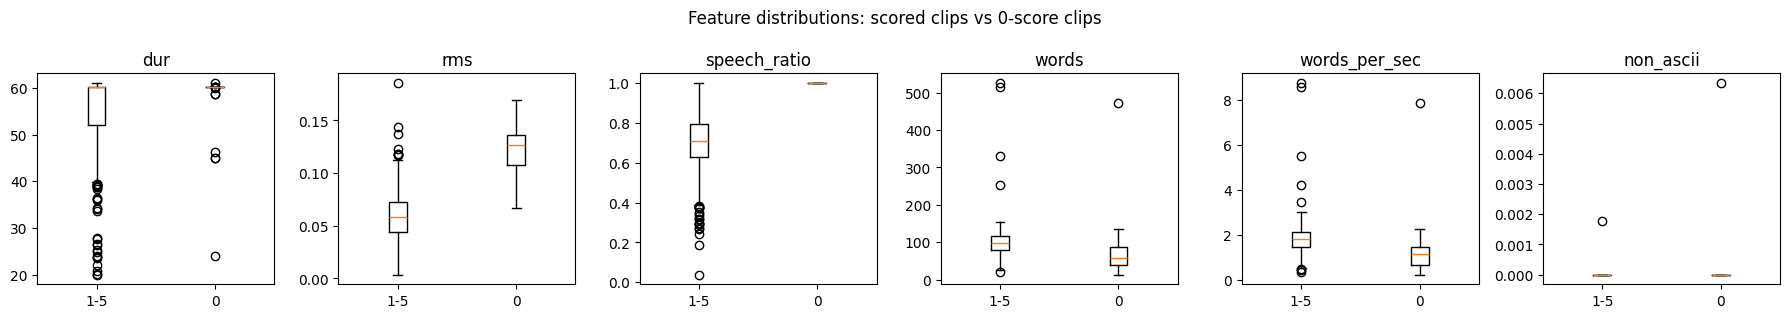

,filename,text,words
17,audio_5055.wav,"Well, the wind dropped on my skin, I felt so free from the wind. Every time I would leave my home, I could make myself forget, at least, all that ...",51
30,audio_5066.wav,"The best thing about our life was when we were little, we were living at the same home but we don't talk to each other. I don't know the deal is r...",73
41,audio_5069.wav,Okay. This place is called the White House. I think it is time to go back to the forest.,19
49,audio_5073.wav,"In the market The and even audible in the road also. The problem was to keep changes day by day from the morning to evening. In the morning, the c...",43
51,audio_5039.wav,"So Home. The troops are gone. It's a livelihood for I think it's very important to the the future land, exercise and unleash their creativity. The...",39
73,audio_5056.wav,The circuit breaker relates the safety of this computer circuit. The stimulus chain is the key to the treatment and helping to protect the human. ...,37
96,audio_5062.wav,I have a lot of friends who have had a lot of anxiety. They are very isolated because they never made it through the times that I enjoyed. I don't...,86
111,audio_5037.wav,"I think the friends are amazing. They taught me, people, family, people. Also people who are going in for a family now. And all my friends who are...",94
122,audio_5054.wav,"It's Wednesday morning in the city centre and we have a lot of local food for the market there and it's a busy day. Fresh fruits from the garden, ...",51
133,audio_5057.wav,"There are so many best days in my life. One of the best days is the result of the film cast. Whenever I saw a teacher, she was a very happy person...",36


In [7]:
is_zero = labels < CFG["zero_cut"]
show = ["dur", "rms", "speech_ratio", "words", "words_per_sec", "non_ascii"]
fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.2))
for ax, f in zip(axes, show):
    ax.boxplot([F_TR.loc[~is_zero, f], F_TR.loc[is_zero, f]])
    ax.set_xticks([1, 2], ["1-5", "0"])
    ax.set_title(f)
plt.suptitle("Feature distributions: scored clips vs 0-score clips"); plt.tight_layout(); plt.show()

pd.set_option("display.max_colwidth", 150)
display(train_df.loc[is_zero, [FNAME, "text"]].assign(words=F_TR.loc[is_zero, "words"]).head(10))

## 6. Cross-validation folds
Shared by both stages so every out-of-fold prediction is honest. Stratified on the half-point label grid.

In [8]:
strat = np.round(labels * 2).astype(int)
skf = StratifiedKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=CFG["seed"])
folds = list(skf.split(np.zeros(N_TR), strat))
fold_id = np.zeros(N_TR, int)
for k, (_, va) in enumerate(folds):
    fold_id[va] = k

## 7. Stage 1: unscorable (0-score) detector
Logistic regression on log-scaled acoustic + transcript features. It outputs `p0`, a probability, so uncertain clips are only partly pulled toward 0.

Detector OOF ROC-AUC: 0.9817


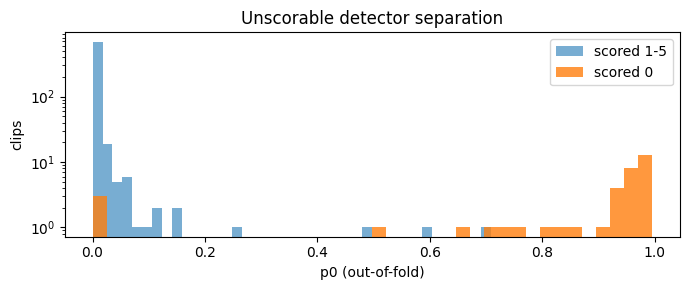

In [9]:
def prep(X):
    return np.log1p(X[FEATS].clip(lower=0).values)

y0 = is_zero.astype(int)
p0_oof = np.zeros(N_TR)
make_clf = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))
for tr, va in folds:
    clf = make_clf().fit(prep(F_TR.iloc[tr]), y0[tr])
    p0_oof[va] = clf.predict_proba(prep(F_TR.iloc[va]))[:, 1]

clf_full = make_clf().fit(prep(F_TR), y0)
p0_train_in = clf_full.predict_proba(prep(F_TR))[:, 1]
p0_test = clf_full.predict_proba(prep(F_TE))[:, 1]
print(f"Detector OOF ROC-AUC: {roc_auc_score(y0, p0_oof):.4f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(p0_oof[~is_zero], bins=40, alpha=0.6, label="scored 1-5")
ax.hist(p0_oof[is_zero], bins=40, alpha=0.8, label="scored 0")
ax.set(yscale="log", xlabel="p0 (out-of-fold)", ylabel="clips", title="Unscorable detector separation")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Stage 2: DeBERTa-v3 grammar regressor
* Trained only on clips scored 1–5 (0s would act as extreme outliers in the MSE loss).
* Folds train in parallel, one per GPU (a pool hands out free GPUs).
* fp32 weights with fp16 autocast + gradient scaling; dynamic padding; larger batches for inference.
* For each fold we keep the best epoch's predictions on the validation fold, the test set and the fold's own training rows (for the in-sample training RMSE).

In [10]:
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

tok = AutoTokenizer.from_pretrained(CFG["text_model"])
collate = DataCollatorWithPadding(tok)
TXT_TR = train_df["text"].fillna("").values
TXT_TE = test_df["text"].fillna("").values

class TextDS(Dataset):
    def __init__(self, texts, y=None):
        self.enc = tok(list(texts), truncation=True, max_length=CFG["max_len"])
        self.y = y
    def __len__(self):
        return len(self.enc["input_ids"])
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        if self.y is not None:
            item["labels"] = float(self.y[i])
        return item

def amp_ctx(device):
    return torch.autocast(device_type="cuda", dtype=torch.float16,
                          enabled=CFG["amp"] and device.startswith("cuda"))

@torch.no_grad()
def predict(model, texts, device):
    # sort by length so each batch pads to a similar size, then restore order
    order = np.argsort([len(t) for t in texts])
    loader = DataLoader(TextDS(texts[order]), batch_size=CFG["eval_batch"], collate_fn=collate)
    model.eval(); out = []
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        with amp_ctx(device):
            out.append(model(**b).logits.squeeze(-1).float().cpu().numpy())
    preds = np.empty(len(texts)); preds[order] = np.concatenate(out)
    return preds

gpu_pool = queue.Queue()
for d in DEVICES:
    gpu_pool.put(d)
init_lock = threading.Lock()
AutoModelForSequenceClassification.from_pretrained(CFG["text_model"], num_labels=1); gc.collect()  # warm the cache once

def train_fold(k):
    tr, va = folds[k]
    tr_nz = tr[labels[tr] >= CFG["zero_cut"]]          # stage 2 learns grammar on scorable clips only
    device = gpu_pool.get()
    try:
        with init_lock:
            seed_all(CFG["seed"] + k)
            model = AutoModelForSequenceClassification.from_pretrained(
                CFG["text_model"], num_labels=1).float().to(device)
        g = torch.Generator().manual_seed(CFG["seed"] + k)
        loader = DataLoader(TextDS(TXT_TR[tr_nz], labels[tr_nz]), batch_size=CFG["batch_size"],
                            shuffle=True, collate_fn=collate, generator=g)
        opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=0.01)
        steps = len(loader) * CFG["epochs"]
        sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * steps), steps)
        scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"] and device.startswith("cuda"))
        va_nz = va[labels[va] >= CFG["zero_cut"]]
        best, keep, history = np.inf, None, []

        for ep in range(CFG["epochs"]):
            model.train()
            for b in loader:
                b = {kk: v.to(device) for kk, v in b.items()}
                y = b.pop("labels").float()
                with amp_ctx(device):
                    logits = model(**b).logits.squeeze(-1)
                loss = torch.nn.functional.mse_loss(logits.float(), y)
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sch.step(); opt.zero_grad()

            vp = np.clip(predict(model, TXT_TR[va], device), 1, 5)
            score = rmse(labels[va_nz], vp[np.isin(va, va_nz)])     # model selection on 1-5 clips
            history.append(score)
            print(f"[{device}] fold {k} epoch {ep}  val RMSE (1-5 clips) {score:.4f}", flush=True)
            if score < best:
                best = score
                keep = (vp, predict(model, TXT_TR[tr], device), predict(model, TXT_TE, device))

        print(f"==> [{device}] fold {k} best {best:.4f}", flush=True)
        del model, opt; gc.collect(); torch.cuda.empty_cache()
        return k, keep, history
    finally:
        gpu_pool.put(device)

reg_oof = np.zeros(N_TR)
reg_test = np.zeros((CFG["n_folds"], len(test_df)))
reg_in_sum, reg_in_cnt = np.zeros(N_TR), np.zeros(N_TR)
histories = {}

with ThreadPoolExecutor(max_workers=len(DEVICES)) as ex:
    for k, (vp, trp, tp), hist in ex.map(train_fold, range(CFG["n_folds"])):
        tr, va = folds[k]
        reg_oof[va] = vp
        reg_in_sum[tr] += np.clip(trp, 1, 5); reg_in_cnt[tr] += 1
        reg_test[k] = tp
        histories[k] = hist

reg_train_in = reg_in_sum / np.maximum(reg_in_cnt, 1)
reg_test_mean = np.clip(reg_test.mean(axis=0), 1, 5)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

...

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

[cuda:1] fold 2 epoch 0  val RMSE (1-5 clips) 0.7730
[cuda:0] fold 3 epoch 0  val RMSE (1-5 clips) 0.7243
[cuda:1] fold 2 epoch 1  val RMSE (1-5 clips) 0.6443
[cuda:0] fold 3 epoch 1  val RMSE (1-5 clips) 1.0305
[cuda:0] fold 3 epoch 2  val RMSE (1-5 clips) 0.7316
[cuda:1] fold 2 epoch 2  val RMSE (1-5 clips) 0.8539
[cuda:0] fold 3 epoch 3  val RMSE (1-5 clips) 0.7700
[cuda:1] fold 2 epoch 3  val RMSE (1-5 clips) 0.8566
[cuda:0] fold 3 epoch 4  val RMSE (1-5 clips) 0.7474
==> [cuda:0] fold 3 best 0.7243


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

[cuda:1] fold 2 epoch 4  val RMSE (1-5 clips) 0.7753
==> [cuda:1] fold 2 best 0.6443
[cuda:0] fold 4 epoch 0  val RMSE (1-5 clips) 0.8463
[cuda:0] fold 4 epoch 1  val RMSE (1-5 clips) 0.6491
[cuda:0] fold 4 epoch 2  val RMSE (1-5 clips) 0.6161
[cuda:0] fold 4 epoch 3  val RMSE (1-5 clips) 0.6295
[cuda:0] fold 4 epoch 4  val RMSE (1-5 clips) 0.6632
==> [cuda:0] fold 4 best 0.6161


## 9. Combine stages and evaluate

In [11]:
final_oof   = np.clip((1 - p0_oof) * reg_oof, 0, 5)
final_train = np.clip((1 - p0_train_in) * reg_train_in, 0, 5)
final_test  = np.clip((1 - p0_test) * reg_test_mean, 0, 5)

nz = ~is_zero
results = pd.DataFrame([
    ["Regressor only, OOF (all clips)",         rmse(labels, reg_oof),        pearsonr(labels, reg_oof)[0]],
    ["Two-stage, OOF (all clips)",              rmse(labels, final_oof),      pearsonr(labels, final_oof)[0]],
    ["Two-stage, OOF (1-5 clips only)",         rmse(labels[nz], final_oof[nz]), pearsonr(labels[nz], final_oof[nz])[0]],
    ["Two-stage, TRAINING RMSE (in-sample)",    rmse(labels, final_train),    pearsonr(labels, final_train)[0]],
], columns=["Evaluation", "RMSE", "Pearson"]).round(4)
results.to_csv(os.path.join(CFG["out_dir"], "cv_results.csv"), index=False)
display(results)

fold_rmse = [rmse(labels[va], final_oof[va]) for _, va in folds]
print("Per-fold OOF RMSE:", np.round(fold_rmse, 4))

,Evaluation,RMSE,Pearson
0,"Regressor only, OOF (all clips)",0.9345,0.6939
1,"Two-stage, OOF (all clips)",0.6836,0.8425
2,"Two-stage, OOF (1-5 clips only)",0.6660,0.7691
3,"Two-stage, TRAINING RMSE (in-sample)",0.5037,0.9205


Per-fold OOF RMSE: [0.6869 0.7071 0.6701 0.7294 0.6188]


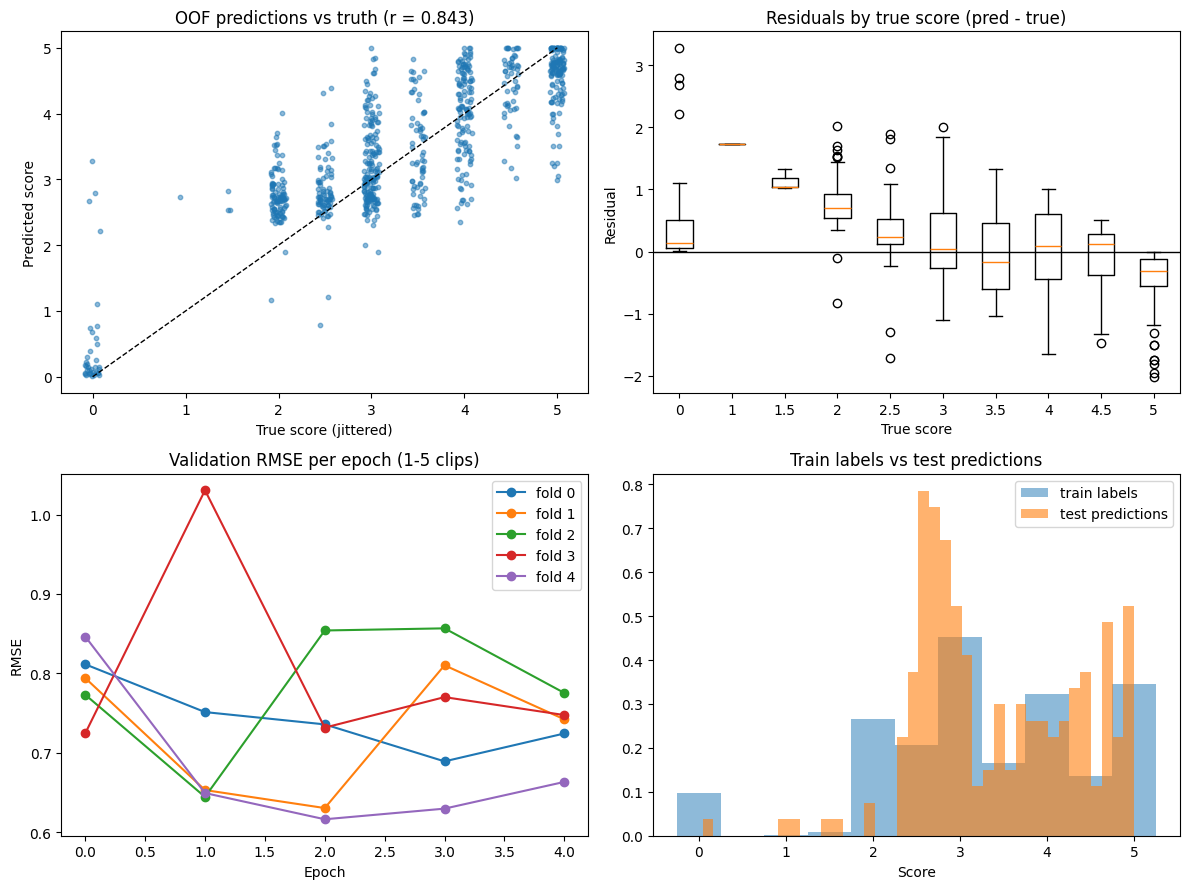

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

ax = axes[0, 0]
ax.scatter(labels + np.random.uniform(-0.08, 0.08, N_TR), final_oof, s=10, alpha=0.5)
ax.plot([0, 5], [0, 5], "k--", lw=1)
ax.set(title=f"OOF predictions vs truth (r = {pearsonr(labels, final_oof)[0]:.3f})",
       xlabel="True score (jittered)", ylabel="Predicted score")

ax = axes[0, 1]
lv = np.unique(labels)
ax.boxplot([final_oof[labels == v] - v for v in lv])
ax.set_xticks(range(1, len(lv) + 1), [f"{v:g}" for v in lv])
ax.axhline(0, color="k", lw=1)
ax.set(title="Residuals by true score (pred - true)", xlabel="True score", ylabel="Residual")

ax = axes[1, 0]
for k, h in histories.items():
    ax.plot(range(len(h)), h, marker="o", label=f"fold {k}")
ax.set(title="Validation RMSE per epoch (1-5 clips)", xlabel="Epoch", ylabel="RMSE"); ax.legend()

ax = axes[1, 1]
ax.hist(labels, bins=np.arange(-0.25, 5.5, 0.5), alpha=0.5, density=True, label="train labels")
ax.hist(final_test, bins=40, alpha=0.6, density=True, label="test predictions")
ax.set(title="Train labels vs test predictions", xlabel="Score"); ax.legend()

plt.tight_layout(); plt.show()

## 10. Submission

In [13]:
submission = pd.DataFrame({SUB_FNAME: test_df[TEST_FNAME].values, SUB_LABEL: final_test})
assert len(submission) == len(test_df) and submission[SUB_LABEL].between(0, 5).all()
submission.to_csv(os.path.join(CFG["out_dir"], "submission.csv"), index=False)
print(f"Wrote {len(submission)} rows | range {final_test.min():.2f} to {final_test.max():.2f} | "
      f"clips with p0 > 0.5: {(p0_test > 0.5).sum()}")
submission.head()

Wrote 216 rows | range 0.04 to 5.00 | clips with p0 > 0.5: 3


,filename,label
0,audio_128.wav,3.111305
1,audio_156.wav,4.181048
2,audio_19.wav,4.893443
3,audio_108.wav,2.569133
4,audio_206.wav,2.304346


## 11. Report

In [14]:
r = results.set_index("Evaluation")
display(Markdown(f'''
### Approach
A two-stage pipeline. Stage 1 detects clips that receive a 0 (outside the 1–5 rubric; {is_zero.sum()} of {N_TR} training clips) from acoustic and transcript features.
Stage 2 is a DeBERTa-v3 regressor fine-tuned on Whisper transcripts of scorable clips. The final score is the expected value `(1 − p0) × grammar_score`.

### Preprocessing
* Audio resampled to 16 kHz mono; decoded in parallel across CPU cores.
* Acoustic features: duration, RMS loudness, speech seconds and ratio (energy-based voice activity, 30 dB threshold), count and length of pauses > 0.5 s.
* Transcription with `{CFG["asr_model"]}` (greedy, 30 s chunks, batched across all GPUs). Casing and punctuation kept, since they carry grammatical structure.
* Transcript features: word count, words per second, lexical diversity, filler words, non-ASCII ratio, mean word length.

### Pipeline architecture
1. Parallel audio decode → acoustic features.
2. Multi-GPU Whisper → transcripts (cached).
3. Logistic regression (standardized log features) → `p0`. OOF ROC-AUC = {roc_auc_score(y0, p0_oof):.3f}.
4. `{CFG["text_model"]}` regression head, {CFG["n_folds"]}-fold stratified CV, {CFG["epochs"]} epochs, lr {CFG["lr"]}, best epoch per fold, folds trained in parallel on {len(DEVICES)} device(s).
5. Combine, clip to [0, 5], average the fold models for test.

### Evaluation results
| Evaluation | RMSE | Pearson |
|---|---|---|
''' + "\n".join(f"| {i} | {row.RMSE:.4f} | {row.Pearson:.4f} |" for i, row in r.iterrows()) + f'''

**Training RMSE (required): {r.loc["Two-stage, TRAINING RMSE (in-sample)", "RMSE"]:.4f}.** This is measured on clips the models saw during training, so it is optimistic.
The out-of-fold RMSE ({r.loc["Two-stage, OOF (all clips)", "RMSE"]:.4f}) is the honest estimate of test performance.

### Observations
* Comparing the regressor-only and two-stage rows shows how much handling the 0 group contributes.
* The residual plot shows whether extreme scores are compressed toward the mean, which is typical for MSE regression on a small dataset.
* Known limitation: Whisper smooths some disfluencies and grammatical slips, which removes part of the signal the rubric describes.
'''))


### Approach
A two-stage pipeline. Stage 1 detects clips that receive a 0 (outside the 1–5 rubric; 37 of 769 training clips) from acoustic and transcript features.
Stage 2 is a DeBERTa-v3 regressor fine-tuned on Whisper transcripts of scorable clips. The final score is the expected value `(1 − p0) × grammar_score`.

### Preprocessing
* Audio resampled to 16 kHz mono; decoded in parallel across CPU cores.
* Acoustic features: duration, RMS loudness, speech seconds and ratio (energy-based voice activity, 30 dB threshold), count and length of pauses > 0.5 s.
* Transcription with `openai/whisper-medium.en` (greedy, 30 s chunks, batched across all GPUs). Casing and punctuation kept, since they carry grammatical structure.
* Transcript features: word count, words per second, lexical diversity, filler words, non-ASCII ratio, mean word length.

### Pipeline architecture
1. Parallel audio decode → acoustic features.
2. Multi-GPU Whisper → transcripts (cached).
3. Logistic regression (standardized log features) → `p0`. OOF ROC-AUC = 0.982.
4. `microsoft/deberta-v3-base` regression head, 5-fold stratified CV, 5 epochs, lr 2e-05, best epoch per fold, folds trained in parallel on 2 device(s).
5. Combine, clip to [0, 5], average the fold models for test.

### Evaluation results
| Evaluation | RMSE | Pearson |
|---|---|---|
| Regressor only, OOF (all clips) | 0.9345 | 0.6939 |
| Two-stage, OOF (all clips) | 0.6836 | 0.8425 |
| Two-stage, OOF (1-5 clips only) | 0.6660 | 0.7691 |
| Two-stage, TRAINING RMSE (in-sample) | 0.5037 | 0.9205 |

**Training RMSE (required): 0.5037.** This is measured on clips the models saw during training, so it is optimistic.
The out-of-fold RMSE (0.6836) is the honest estimate of test performance.

### Observations
* Comparing the regressor-only and two-stage rows shows how much handling the 0 group contributes.
* The residual plot shows whether extreme scores are compressed toward the mean, which is typical for MSE regression on a small dataset.
* Known limitation: Whisper smooths some disfluencies and grammatical slips, which removes part of the signal the rubric describes.
